# Models for the Unpredictable: AR(1) to ARMA(1,1)

> 从「为什么无法准确预测」出发，而不是从公式出发。

这份教案讨论的对象是时间序列：它们不是完全可预测的机械钟摆，也不是完全没有结构的噪声。AR、MA 与 ARMA 是人们为了描述这种 **有规律、但总会有新意外** 的现象，逐步提出的模型。

## 名称先记住

- **AR** = **AutoRegressive**，自回归模型：用过去的序列值解释现在；
- **MA** = **Moving Average**，移动平均模型：用当前与过去的随机冲击解释现在；这里不是技术分析里的滚动均线；
- **ARMA** = **AutoRegressive Moving Average**，自回归移动平均模型：同时包含上述两种机制；
- 括号中的数字是阶数（order）。例如 AR(2) 代表使用两个过去的序列值；MA(2) 代表保留两个过去冲击的余波；ARMA(1,1) 分别使用一阶 AR 和一阶 MA。

## 课程路线

1. 什么叫「不可预测」：新冲击 $\varepsilon_t$ 从哪里来？
2. AR(1)：今天会不会像昨天？
3. AR(2)：为什么需要记住前天？为什么它能描述振荡？
4. MA(1)、MA(2)：不是状态有记忆，而是意外的余波还在。
5. ARMA(1,1)：状态延续与冲击余波同时存在。
6. spread half-life：带平衡位置的 AR(1)。

## 0. 先准备实验工具

下面先不使用真实价格，也不加入随机的新冲击。我们在 $t=0$ 给系统一个大小为 1 的**已知初始冲击**；从 $t=1$ 开始令所有新的 $\varepsilon_t=0$。

所以每张图都是模型在 **零预测误差** 下的理想预测路径：模型已经知道初始冲击，而未来没有任何意外。这会把 AR、MA 与 ARMA 的结构差异从随机折线中清楚地分离出来。

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
def plot_ideal_path(values, title, label):
    fig, ax = plt.subplots(figsize=(11, 3.6))
    ax.plot(np.arange(len(values)), values, marker="o", ms=3, lw=2,
            color="#1769aa", label=label)
    ax.axhline(0, color="#78909c", lw=0.8)
    ax.set(title=title, xlabel="time t", ylabel="X(t)")
    ax.legend(loc="upper right", frameon=True)
    plt.show()

## 1. 先问一个朴素问题：为什么要建模？

如果一个系统完全可预测，我们不需要概率模型；只要写下物理规律，就可以一路算到未来。

但金融价格、利率、成交量、需求等序列不是这样。它们的过去常常含有可利用的线索，却永远有一部分今天才出现、无法由昨天推知的变化。

我们把这部分新信息记为：

$$\varepsilon_t$$

它通常被称为 **innovation（创新项）** 或 **shock（冲击）**。它不是「模型失败」的残差，而是模型承认现实存在新消息的方式。

从这里起，$t$ 表示当前离散时刻；$t-1$ 是前一时刻（例如昨天），$t-2$ 是前两时刻（例如前天）。

## 2. AR(1)：走一步看一步

最小的问题是：**如果只允许看昨天，昨天能告诉今天什么？**

$$X_t=c+\phi X_{t-1}+\varepsilon_t$$

这就是 AR(1)：一阶自回归（autoregression）。

- $X_t$：当前时刻的序列数值；$X_{t-1}$：前一时刻的数值；
- $c$：常数项／截距。它表示不依赖过去状态的固定基准变化；
- $\phi$：AR 系数，前一时刻的状态延续到当前的比例；
- $\varepsilon_t$：当前时刻新发生、过去无法预测的创新项。

“走一步看一步”是很好的直觉，但要更精确：它不是拿昨天直接复制今天，而是在预测今天时，先用昨天给出可预测部分，剩下的交给新的随机冲击。

### AR(1) 最初要解决什么？

它是为了描述 **短期持续性**：例如今天偏高，明天也倾向偏高；但不会永远精确地沿用昨天。AR(1) 的系数 $\phi$ 决定旧状态在下一步保留多少。

这里的曲线本身就是理想预测曲线：由于未来 $\varepsilon_t=0$，实际值会与预测完全重合，因此没有必要画两条重叠的线。

严格一致的生活数学模型是：每次采样间隔 $\Delta t$ 相等时，温差 $D$ 的热传导／牛顿冷却离散式为 $D_{t+1}=e^{-k\Delta t}D_t$。因此 AR(1) 的 $0<\phi<1$ 与它完全同形，且 $\phi=e^{-k\Delta t}$ 是固定常数。

同样，$\phi>1$ 严格对应于不受资源与环境约束的理想人口增长状态：若每一期人口都按固定比例 $\phi$ 增长，则 $N_{t+1}=\phi N_t$，这正是 AR(1) 的无脉冲形式。

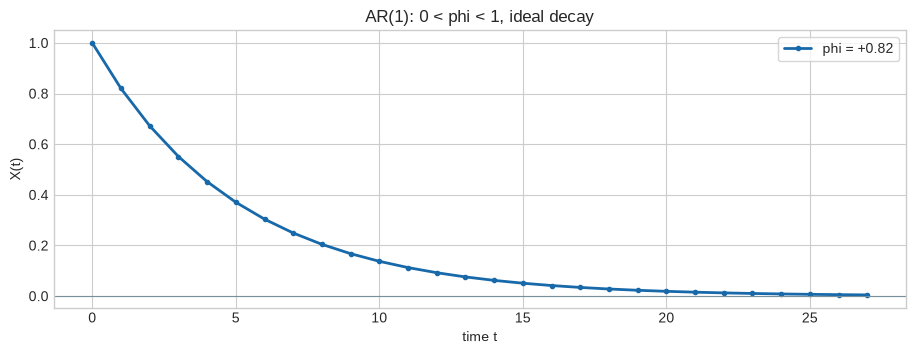

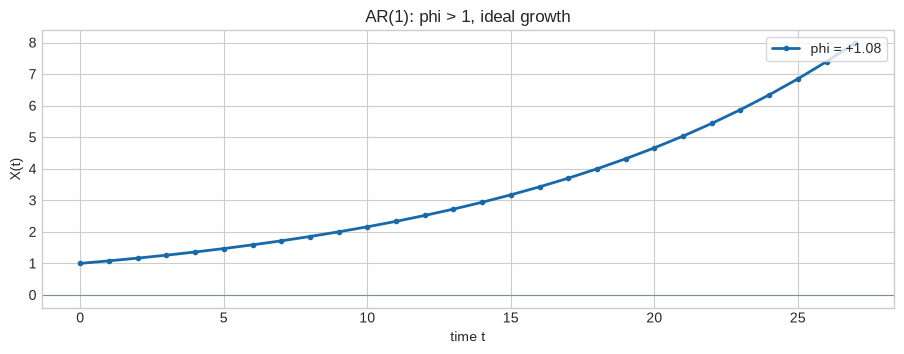

In [3]:
n = 28
def ar1_ideal(phi, x0=1.0):
    x = np.zeros(n)
    x[0] = x0                 # known initial displacement
    for t in range(1, n):
        x[t] = phi * x[t - 1] # every future epsilon(t) = 0
    return x

plot_ideal_path(ar1_ideal(+0.82),
                "AR(1): 0 < phi < 1, ideal decay", "phi = +0.82")

plot_ideal_path(ar1_ideal(+1.08),
                "AR(1): phi > 1, ideal growth", "phi = +1.08")

## 3. AR(2)：只看昨天够不够？

如果系统具有惯性、回摆或节奏，只看一步前可能不够。于是我们问：**前天的信息是否仍然有独立价值？**

$$X_t=c+\phi_1X_{t-1}+\phi_2X_{t-2}+\varepsilon_t$$

其中 $X_t$ 是当前值；$c$ 是常数项；$X_{t-1}$、$X_{t-2}$ 分别是前一与前两时刻的值；$\phi_1$、$\phi_2$ 是它们各自的 AR 系数；$\varepsilon_t$ 是当前的新创新项。

AR(2) 不是「二阶地走一步看一步」，而是预测今天时同时参考前一时刻和前两时刻。它是从一维记忆扩展到两步记忆。

### AR(2) 最初要解决什么？

AR(1) 只有一个衰减节奏。若数据表现出 **回摆、周期感或两步记忆**，就要问：知道前天以后，能否比只知道昨天预测得更好？在 AR(2) 中，$\phi_1$ 与 $\phi_2$ 可以各自为正或负；它们的组合决定是平滑延续，还是带有真正回摆感的阻尼振荡。

尤其要注意：AR(2) 递推需要两个初始状态。$X_1$ 与 $X_2$ 是已经发生、分别观察到的两个值；从 $X_3$ 开始，模型才使用 $X_t=\phi_1X_{t-1}+\phi_2X_{t-2}$ 进行预测。

严格对应的连续动力学是二阶方程，例如质量—弹簧—阻尼系统：

$$m\frac{d^2x}{dt^2}+c\frac{dx}{dt}+kx=0$$

这里 $x(t)$ 是位置，$m$ 是质量，$c$ 是阻尼系数，$k$ 是弹簧刚度。二阶方程需要同时知道位置和速度；离散地看，最近两个位置 $X_t,X_{t-1}$ 就携带了当前位置与运动趋势的信息。

最简单的无阻尼振子满足：

$$\frac{d^2x}{dt^2}+\omega^2x=0$$

用等间隔 $\Delta t$ 的中心差分：

$$\frac{x_{t+1}-2x_t+x_{t-1}}{\Delta t^2}+\omega^2x_t=0$$

于是得到：

$$x_{t+1}=\left(2-\omega^2\Delta t^2\right)x_t-x_{t-1}$$

这正是 AR(2) 的形式，且

$$\phi_1=2-\omega^2\Delta t^2,\qquad \phi_2=-1$$

小角度单摆完全同形：$\frac{d^2\theta}{dt^2}+\frac{g}{L}\theta=0$，因此 $\omega^2=g/L$。对等时间采样的正弦振荡，也可以写成 $x_{t+1}=2\cos(\omega\Delta t)x_t-x_{t-1}$。所以 AR(2) 的“前两步”本质上是在离散地保存位置与速度，因而能够产生回摆和振荡。

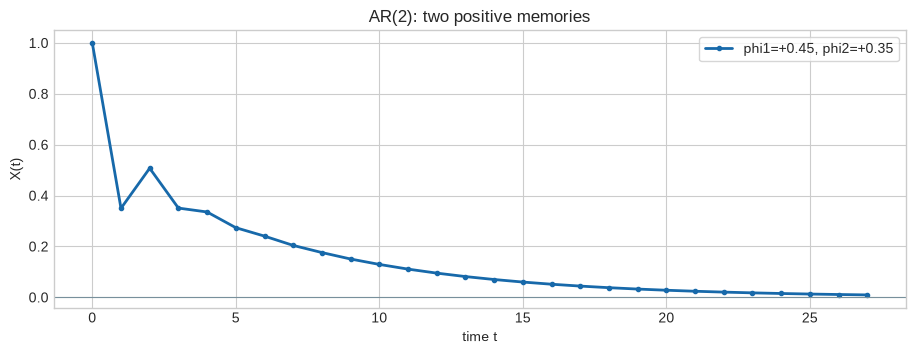

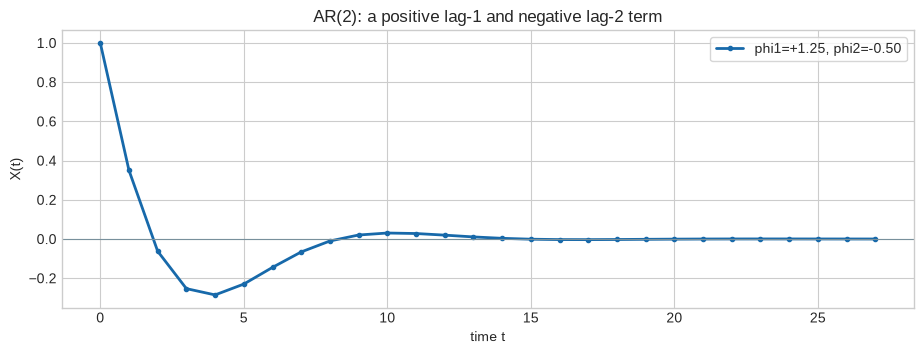

In [4]:
def ar2_ideal(phi1, phi2, x1=1.0, x2=0.35):
    x = np.zeros(n)
    x[0] = x1                 # observed initial value X(1)
    x[1] = x2                 # independently observed X(2)
    for t in range(2, n):
        x[t] = phi1 * x[t - 1] + phi2 * x[t - 2]  # forecast from X(3) onward
    return x

plot_ideal_path(ar2_ideal(+0.45, +0.35),
                "AR(2): two positive memories", "phi1=+0.45, phi2=+0.35")

plot_ideal_path(ar2_ideal(+1.25, -0.50),
                "AR(2): a positive lag-1 and negative lag-2 term", "phi1=+1.25, phi2=-0.50")

### AR(2) 的特殊例子：斐波那契数列

斐波那契递推为：

$$F_t=F_{t-1}+F_{t-2}$$

它是一个无截距、无新冲击的确定性 AR(2)：

$$c=0,\qquad \phi_1=1,\qquad \phi_2=1,\qquad \varepsilon_t=0$$

其中 $F_1,F_2$ 是两个独立给定的初始值。由于两个系数都为正，前一期和前两期会同方向推动当前值；这不是回摆，而是持续增长。特征方程 $r^2-r-1=0$ 的正根为黄金比例 $\frac{1+\sqrt5}{2}>1$，因此数列呈指数增长。

### 生活中的 Fibonacci 发现

这个 AR(2) 结构并不只存在于纸面上。兔子繁殖模型直接给出 $1,1,2,3,5,8,\ldots$；蜜蜂家谱中，雄蜂只有一个亲本、雌蜂有两个亲本，按世代统计祖先数量也会出现 Fibonacci 递推。

植物给我们的是更令人惊喜的空间版本。向日葵种子、松果鳞片、菠萝鳞片和许多植物的叶序，常常可以数出 $3,5,8,13,21,34,55,\ldots$ 这些 Fibonacci 数字。这里的数字不是凭空出现的：植物需要在有限空间里尽可能多地放置叶片、种子或花瓣，同时减少彼此遮挡，让每个生长单元尽量获得阳光、空气和空间。

一种高效率的连续生长规则，是让相邻生长单元之间保持黄金角：

$$\alpha=360^\circ\left(1-\frac{1}{\varphi}\right)\approx137.5077^\circ$$

其中 $\varphi=\frac{1+\sqrt5}{2}$。这个角度不是一个简单分数角：它不会很快重复落在同一条径向线上，因此新叶片会不断填补旧叶片之间的空隙。用一个理想化的叶序模型表示第 $n$ 个生长单元：

$$\theta_n=n\alpha,\qquad r_n=c\sqrt n$$

这里 $\theta_n$ 是绕中心的角度，$r_n$ 是半径，$c$ 控制整体疏密。角度负责错开，半径负责把新单元向外铺开；两者共同实现空间填充。

从俯视图看，这些点会形成两组主要的可见螺旋：一组向顺时针方向，一组向逆时针方向。为了数清这些螺旋，我们会得到一对相邻的 Fibonacci 数，例如 $34$ 与 $55$，或 $55$ 与 $89$。它们的比值越来越接近黄金比例：

$$\frac{F_{n+1}}{F_n}\to\varphi$$

所以，“前两个状态影响当前状态”在这里有两层含义：在纯数列模型中，$F_t=F_{t-1}+F_{t-2}$ 是直接递推；在植物空间结构中，前面已经形成的两组相邻螺旋共同约束新生长单元的空隙位置，最终显现为下一组 Fibonacci 螺旋计数。AR(2) 是这类“两步记忆、共同生成当前结构”的离散数学表达。

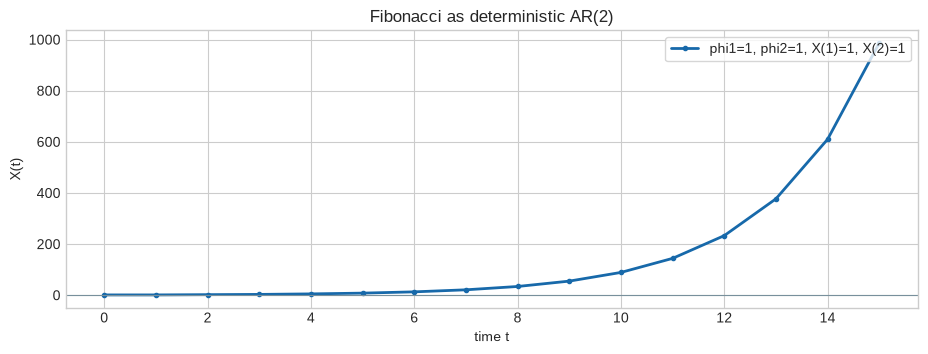

In [5]:
def fibonacci_ar2(phi1=1.0, phi2=1.0, x1=1.0, x2=1.0, steps=16):
    x = np.zeros(steps)
    x[0], x[1] = x1, x2
    for t in range(2, steps):
        x[t] = phi1 * x[t - 1] + phi2 * x[t - 2]
    return x

fib = fibonacci_ar2()
plot_ideal_path(fib, "Fibonacci as deterministic AR(2)",
                "phi1=1, phi2=1, X(1)=1, X(2)=1")

## 4. MA：也许记忆来自意外，而不是状态

另一种朴素猜想是：状态本身不一定会延续，但昨天那次意外的影响可能还没消失。物流流程提供了最直观的生活来源：一笔突发订单会在固定的后续处理环节留下有限、可数的工作量。

$$X_t=\varepsilon_t+\theta\varepsilon_{t-1}$$

这是 MA(1)：一阶移动平均（moving average）。这里的 “average” 不是滚动均线；它是当前与过去冲击的线性组合。

其中 $X_t$ 是当前值；$\varepsilon_t$ 是当前冲击；$\varepsilon_{t-1}$ 是上一时刻发生的冲击；$\theta$ 是 MA 系数，表示上一时刻冲击的余波有多少仍留在今天。

### MA(1) 最初要解决什么？

它描述的是 **冲击的短暂余波**，而不是状态自身不断复制。一次意外会影响今天和明天，但到后天就没有直接影响。

把 $\varepsilon_t$ 想成第 $t$ 天突然到来的一笔额外订单，把 $X_t$ 想成当天需要处理的总工作量。对 MA(1)，这笔订单经过两个固定阶段：

$$\text{下单日}\ \longrightarrow\ \text{次日分拣／备货}$$

订单在当天直接进入系统；到下一天，仍有 $\theta$ 比例的工作量留在分拣或备货环节；再下一天，这笔订单已经走完流程：

$$X_t=\varepsilon_t,\qquad X_{t+1}=\theta\varepsilon_t,\qquad X_{t+2}=0$$

所以 MA(1) 问的不是“昨天的状态会不会继续影响今天”，而是“昨天那件意外会不会在今天留下固定比例的余波”。$\theta>0$ 是同方向余波，$\theta<0$ 是反向修正余波。

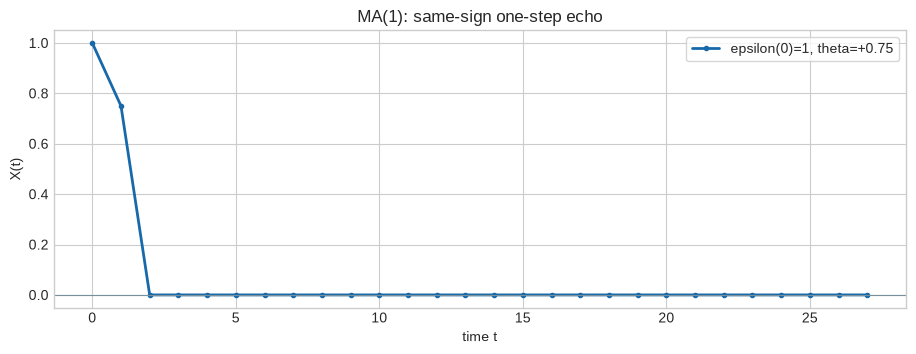

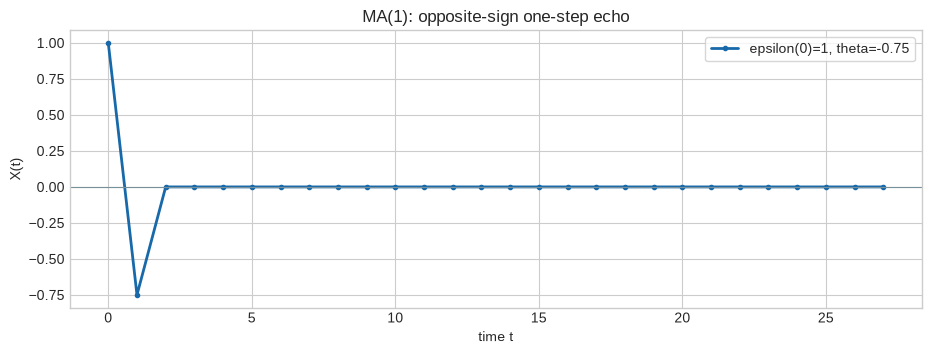

In [6]:
initial_shock = 1.0           # known raw innovation epsilon(0)

def ma1_ideal(theta, epsilon0=initial_shock):
    eps = np.zeros(n)
    eps[0] = epsilon0          # the only raw shock
    x = np.zeros(n)
    for t in range(n):
        x[t] = eps[t] + (theta * eps[t - 1] if t >= 1 else 0.0)
    return x

plot_ideal_path(ma1_ideal(+0.75),
                "MA(1): same-sign one-step echo", "epsilon(0)=1, theta=+0.75")

plot_ideal_path(ma1_ideal(-0.75),
                "MA(1): opposite-sign one-step echo", "epsilon(0)=1, theta=-0.75")

### MA(2)：余波持续两步

$$X_t=\varepsilon_t+\theta_1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}$$

其中 $\theta_1$ 是上一时刻冲击留下的比例，$\theta_2$ 是前两时刻冲击留下的比例。MA(2) 要解决的是：一次冲击的影响不只持续一天，而是有一个有限、可数的两步尾巴。

继续同一笔突发订单的物流故事。现在流程有三个固定阶段：

$$\text{下单日}\ \longrightarrow\ \text{次日分拣／备货}\ \longrightarrow\ \text{再下一日发运／交付}$$

若第 $t$ 天发生订单脉冲 $\varepsilon_t$，它在三个日期的直接贡献为：

$$X_t=\varepsilon_t,\qquad X_{t+1}=\theta_1\varepsilon_t,\qquad X_{t+2}=\theta_2\varepsilon_t,\qquad X_{t+3}=0$$

也就是说：今天订单直接增加工作量；明天还有分拣／备货余波；后天还有发运／交付余波；第三天后这笔订单已经完成。$\theta_1,\theta_2>0$ 表示两个后续环节都增加工作量；若某个系数为负，则该环节体现抵消、取消、库存回补或集中处理后的回落。

若唯一脉冲出现在第 10 天，$\varepsilon_{10}=A$，则 $X_{10}=A$、$X_{11}=\theta_1A$、$X_{12}=\theta_2A$、$X_{13}=0$。这正是黑板中把脉冲放在 $t=10$ 的原因。

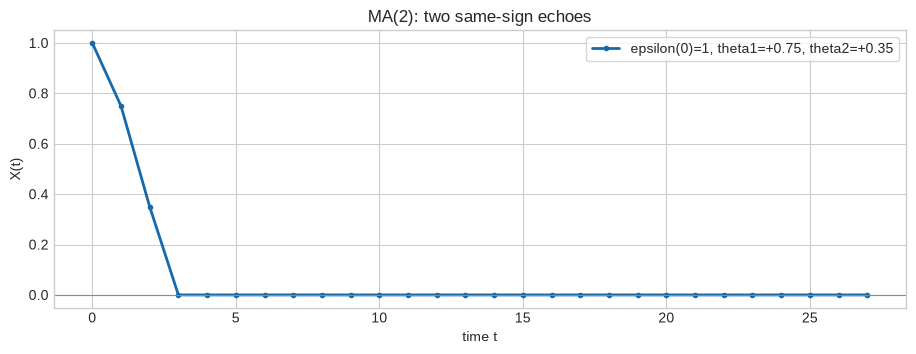

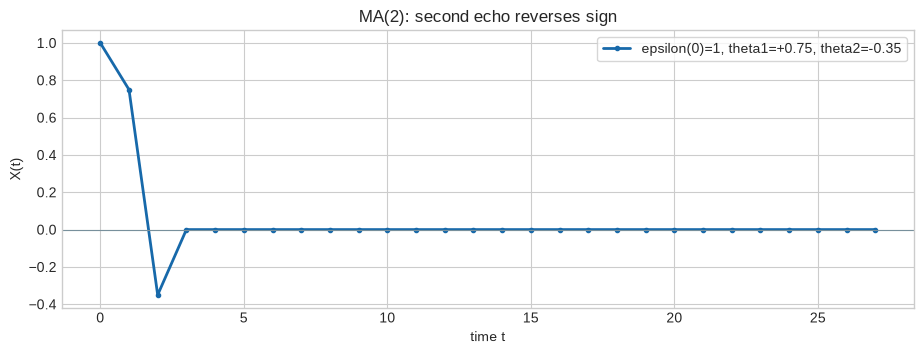

In [7]:
initial_shock = 1.0           # known raw innovation epsilon(0)

def ma2_ideal(theta1, theta2, epsilon0=initial_shock):
    eps = np.zeros(n)
    eps[0] = epsilon0
    x = np.zeros(n)
    for t in range(n):
        x[t] = eps[t]
        if t >= 1: x[t] += theta1 * eps[t - 1]
        if t >= 2: x[t] += theta2 * eps[t - 2]
    return x

plot_ideal_path(ma2_ideal(+0.75, +0.35),
                "MA(2): two same-sign echoes", "epsilon(0)=1, theta1=+0.75, theta2=+0.35")

plot_ideal_path(ma2_ideal(+0.75, -0.35),
                "MA(2): second echo reverses sign", "epsilon(0)=1, theta1=+0.75, theta2=-0.35")

## 5. ARMA(1,1)：两种记忆同时存在

$$X_t=c+\phi X_{t-1}+\varepsilon_t+\theta\varepsilon_{t-1}$$

ARMA(1,1) 同时承认：

- $X_t$ 是当前值，$X_{t-1}$ 是前一时刻值；
- $c$ 是常数项；
- $\phi$ 是 AR 系数：状态有多少延续到下一步；
- $\varepsilon_t$ 是当前新冲击，$\varepsilon_{t-1}$ 是上一时刻冲击；
- $\theta$ 是 MA 系数：上一时刻冲击的余波保留多少到今天。

这是从两个不同的“为什么今天和过去相关”的猜想出发，自然合并得到的模型。

### ARMA(1,1) 会产生什么效果？

它同时处理两种现实：状态本身有延续（AR），而一条新消息也有一小段余波（MA）。因此一次冲击先留下由 $\theta$ 决定的短期回声，随后由 $\phi$ 持续传递；它既不像 MA 那样在有限步后归零，也不只是纯 AR(1) 的单一指数衰减。

### 生活来源一：仓库积压 + 异常订单的专项余波

令 $X_t$ 是仓库在第 $t$ 天的待处理工作量。昨天尚未消化的积压会自然延续到今天，形成 AR 部分：

$$\phi X_{t-1}$$

昨天若突然来了一笔异常大订单 $\varepsilon_{t-1}$，今天除了承接普通积压外，还可能有拆单、人工审核、异常复核等专项工作，形成 MA 部分：

$$\theta\varepsilon_{t-1}$$

因此今天的工作量可拆成：

$$X_t=\underbrace{c}_{\text{日常基准}}+\underbrace{\phi X_{t-1}}_{\text{昨天积压仍未消化}}+\underbrace{\varepsilon_t}_{\text{今天新来的意外订单}}+\underbrace{\theta\varepsilon_{t-1}}_{\text{昨天异常订单的专项余波}}$$

例如 $X_{t-1}=100$、$\phi=0.7$、$\varepsilon_{t-1}=20$、$\theta=0.5$、$\varepsilon_t=8$、$c=0$ 时，$X_t=70+10+8=88$。这里 70 来自积压状态，10 来自昨天异常订单的专项余波，8 是今天新的意外。

### 生活来源二：自然系统的真实状态 + 观测

ARMA 也会从自然系统中自然出现。先看真实温差 $D_t$：在固定采样间隔下，牛顿冷却给出 AR(1) 结构，环境气流、微小热源等自然扰动记为 $w_t$：

$$D_t=\phi D_{t-1}+w_t,\qquad 0<\phi<1$$

仪器实际记录的是带测量噪声的读数：

$$Y_t=D_t+v_t$$

所以我们看到的 $Y_t$ 同时带有真实温差的 AR 记忆，以及观测误差在相邻读数间产生的短期修正；统计上这正会呈现 ARMA 型结构。这里 MA 部分不是人为流程，而是“真实状态”和“我们看见的读数”之间的差。

第二个自然例子是阻尼弹簧或小角度单摆：

$$m\ddot x+c\dot x+kx=f(t)$$

弹簧／摆的自身动力学保留过去状态，离散后给出 AR(2) 型记忆；风、地面震动等自然外力 $f(t)$ 带来新的脉冲；传感器读数再叠加短期观测噪声。于是实际记录的位置序列自然会呈现 ARMA 型结构。

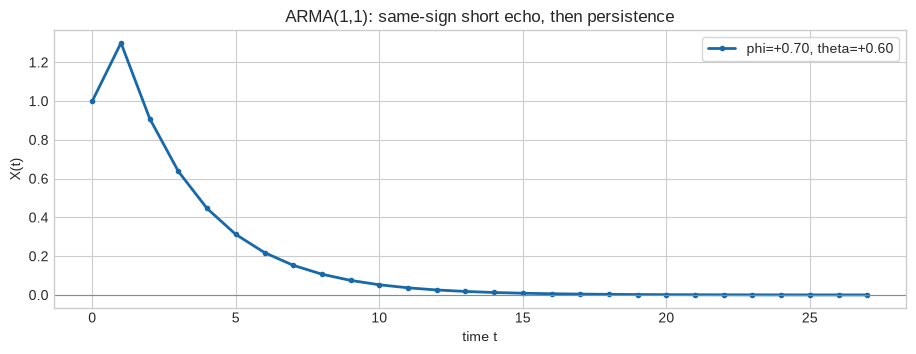

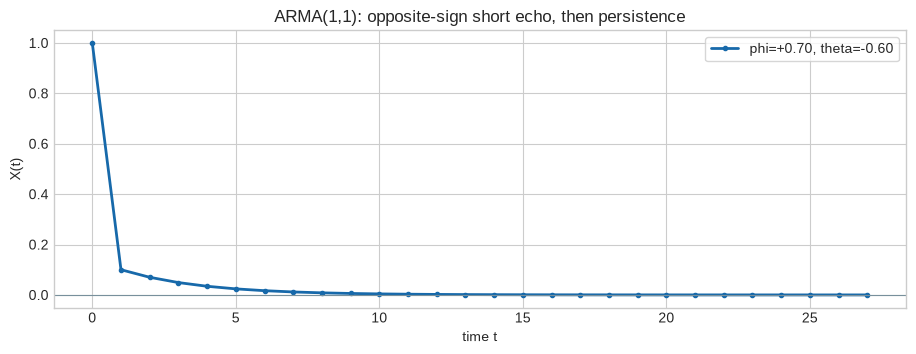

In [8]:
def arma11_ideal(phi, theta):
    eps = np.zeros(n)
    eps[0] = 1.0
    x = np.zeros(n)
    for t in range(n):
        ar_part = phi * x[t - 1] if t >= 1 else 0.0
        ma_part = theta * eps[t - 1] if t >= 1 else 0.0
        x[t] = ar_part + eps[t] + ma_part
    return x

plot_ideal_path(arma11_ideal(+0.70, +0.60),
                "ARMA(1,1): same-sign short echo, then persistence", "phi=+0.70, theta=+0.60")

plot_ideal_path(arma11_ideal(+0.70, -0.60),
                "ARMA(1,1): opposite-sign short echo, then persistence", "phi=+0.70, theta=-0.60")

## 6. spread half-life：它就是带平衡位置的 AR(1)

现在令 $S_t$ 代表第 $t$ 时刻的 spread，$\mu$ 代表它的平衡位置。我们拟合的 half-life 回归是：

$$\Delta S_t=\lambda(S_{t-1}-\mu)+\varepsilon_t$$
$$S_t-S_{t-1}=\lambda(S_{t-1}-\mu)+\varepsilon_t$$

其中 $S_t-S_{t-1}$ 就是原来写作 $\Delta S_t$ 的本期 spread 变化；$S_{t-1}-\mu$ 是昨天偏离平衡位置的距离；$\lambda$ 是均值回复速度；$\varepsilon_t$ 是本期无法预测的冲击。

把右侧展开，再把 $S_{t-1}$ 移到右边：

$$\begin{aligned}
S_t-S_{t-1}&=\lambda S_{t-1}-\lambda\mu+\varepsilon_t\\
S_t&=(1+\lambda)S_{t-1}-\lambda\mu+\varepsilon_t
\end{aligned}$$

定义标准 AR(1) 的系数与截距：

$$\phi=1+\lambda,\qquad c=-\lambda\mu$$

便得到标准形式：

$$S_t=c+\phi S_{t-1}+\varepsilon_t$$

所以 half-life 不是另一种脱离 AR 的模型：它就是 spread 围绕平衡位置 $\mu$ 的 AR(1)。当 $-1<\lambda<0$ 时，$0<\phi<1$，上一期的偏离会按固定比例缩小，正是我们在 AR(1) 与牛顿冷却里已经看到的衰减结构。

也可以把平衡位置从公式中完全拿掉。定义偏离量 $D_t=S_t-\mu$，则：

$$D_t=\phi D_{t-1}+\varepsilon_t$$

这是零均值的标准 AR(1)。half-life 正是这个偏离量衰减到一半所需要的时间。

## 6.1 用真实日线观察瞬时 $\lambda$：SBLK / BHP

下面把第 6 节的关系用于 `quant_data.us_market_days`。我们采用 `quant_dashboard_fixed_beta.py` 的固定 beta 思路：分别对两条**原始价格**做端点去趋势，并令

$$\beta_{\min}=\frac{D(x)^\top D(y)}{D(x)^\top D(x)}.$$

这正是使去趋势后 spread $D(y)-\beta D(x)$ 方差最小的 OLS 投影系数；beta 只用所选样本计算一次，不滚动重估。这里特意不以首日价格归一化：beta 是实际价格单位下的对冲比率，因此修改数据起始日不会因为重新选定“基准价格”而额外改变尺度。定义固定-beta spread：

$$S_t=\widetilde y_t-\beta_{\min}\widetilde x_t.$$

令 $\mu_t$ 为截至 $t$ 的 trailing rolling mean。为了让第 $t$ 根 bar 的分母只包含当时已经知道的信息，我们在 AR(1) 方程中使用前一根的均值 $\mu_{t-1}$：

$$\lambda_{\mathrm{raw},t}=\frac{S_t-S_{t-1}}{S_{t-1}-\mu_{t-1}}.$$

因此，当 spread 在前一日位于均值上方（下方）且随后继续上升（下降）时，$\lambda_{\mathrm{instant}}>0$，是局部发散；当它向均值方向移动时，$\lambda_{\mathrm{instant}}<0$，是局部回归。图中黑色虚线是 $\mu$，两条边界是 rolling $\mu\pm2\sigma$；在这条 $\pm2\sigma$ 通道内，每一段的填充颜色直接编码该日的 $\lambda_{\mathrm{instant}}$。横轴是连续的共同交易日序号，周末和节假日不会留下空档。这个逐 bar 比值在 $S_{t-1}$ 很接近 $\mu_{t-1}$ 时具有结构性奇点：极小的正负分母会把视觉上相近的一步移动放大成截然不同的正负极端值。因此只有当前一日偏离至少为 0.25 个 rolling $\sigma$ 时才把 lambda 视为可解释；其他 bar 显示为空白，并把原始比值另存以供审计。

In [ ]:
# 真实数据：固定最小方差 beta、滚动 mu 与逐日瞬时 lambda
import numpy as np
import pandas as pd
import pymysql
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

TICKER_Y, TICKER_X = 'SBLK', 'BHP'
START_DATE = '2026-01-02'
ROLLING_WINDOW = 20  # 交易日；可自行调整
DB_CONFIG = {
    'host': 'localhost', 'user': 'quant', 'password': '1q2w3e', 'database': 'quant_data'
}

query = '''
SELECT a.trade_date AS date, a.price AS y_price, b.price AS x_price
FROM us_market_days AS a
JOIN us_market_days AS b
  ON b.ticker = %(ticker_x)s AND b.trade_date = a.trade_date
WHERE a.ticker = %(ticker_y)s AND a.trade_date >= %(start_date)s
ORDER BY a.trade_date
'''
with pymysql.connect(**DB_CONFIG) as connection:
    data = pd.read_sql(query, connection, params={
        'ticker_y': TICKER_Y, 'ticker_x': TICKER_X, 'start_date': START_DATE
    })

data['date'] = pd.to_datetime(data['date'])
data[['y_price', 'x_price']] = data[['y_price', 'x_price']].apply(pd.to_numeric, errors='coerce')
data = data.dropna().drop_duplicates('date').sort_values('date').reset_index(drop=True)
if len(data) < ROLLING_WINDOW + 1:
    raise ValueError(f'至少需要 {ROLLING_WINDOW + 1} 根共同日线；当前只有 {len(data)} 根。')

def endpoint_detrend(values):
    values = np.asarray(values, dtype=float)
    return values - np.linspace(values[0], values[-1], len(values))

# dashboard 的核心算法是端点去趋势的最小方差投影；此处保留原始价格单位。
dy = endpoint_detrend(data['y_price'])
dx = endpoint_detrend(data['x_price'])
beta_min_variance = float(np.dot(dx, dy) / np.dot(dx, dx))

data['spread'] = data['y_price'] - beta_min_variance * data['x_price']
data['mu'] = data['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
data['rolling_sigma'] = data['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=0)
data['upper_2sigma'] = data['mu'] + 2 * data['rolling_sigma']
data['lower_2sigma'] = data['mu'] - 2 * data['rolling_sigma']
data['zscore'] = (data['spread'] - data['mu']) / data['rolling_sigma']
data['spread_change'] = data['spread'].diff()
data['lag_deviation'] = data['spread'].shift(1) - data['mu'].shift(1)
data['lag_sigma'] = data['rolling_sigma'].shift(1)
data['lag_zscore'] = data['lag_deviation'] / data['lag_sigma']
data['lambda_instant_raw'] = data['spread_change'] / data['lag_deviation']
MIN_ABS_LAG_ZSCORE = 0.25
# 对 lambda 的分母做同号下限截断，而非删除靠近均值的 bar。
data['lag_zscore_used'] = np.sign(data['lag_zscore']) * np.maximum(data['lag_zscore'].abs(), MIN_ABS_LAG_ZSCORE)
data.loc[data['lag_zscore'].eq(0) | data['lag_zscore'].isna(), 'lag_zscore_used'] = np.nan
data['lag_deviation_used'] = data['lag_zscore_used'] * data['lag_sigma']
data['lambda_initial'] = data['spread_change'] / data['lag_deviation_used']
# 若近均值的符号穿越仍给出 lambda < -1，将 previous z 的符号反转后重估。
data['crossing_reestimate'] = data['lambda_initial'].lt(-1) & data['lag_zscore'].abs().lt(MIN_ABS_LAG_ZSCORE)
data.loc[data['crossing_reestimate'], 'lag_zscore_used'] *= -1
data['lag_deviation_used'] = data['lag_zscore_used'] * data['lag_sigma']
data['lambda_instant'] = data['spread_change'] / data['lag_deviation_used']
data['normalized_spread_move'] = data['spread_change'] / data['lag_sigma']
data['phi_instant'] = 1 + data['lambda_instant']
mean_reverting = data['phi_instant'].between(0, 1, inclusive='neither')
data['half_life_bars'] = np.nan
data.loc[mean_reverting, 'half_life_bars'] = -np.log(2) / np.log(data.loc[mean_reverting, 'phi_instant'])
diverging = data['phi_instant'].gt(1)
data['doubling_time_bars'] = np.nan
data.loc[diverging, 'doubling_time_bars'] = np.log(2) / np.log(data.loc[diverging, 'phi_instant'])
data['life_time_bars'] = data['half_life_bars'].combine_first(data['doubling_time_bars'])
data['life_type'] = np.select([mean_reverting, diverging], ['half-life (reversion)', 'doubling time (divergence)'], default='undefined')
data['trading_bar'] = np.arange(len(data))

print(f'共同日线：{len(data)} 根，{data.date.min():%Y-%m-%d} 至 {data.date.max():%Y-%m-%d}')
print(f'固定最小方差 beta ({TICKER_Y} - beta × {TICKER_X}) = {beta_min_variance:.6f}')
data[['trading_bar', 'date', 'y_price', 'x_price', 'spread', 'mu', 'lag_zscore', 'lag_zscore_used', 'lambda_initial', 'lambda_instant', 'phi_instant', 'half_life_bars', 'doubling_time_bars', 'life_type']].tail(10)

In [ ]:
# 连续横轴只表示共同交易日；lambda 直接填入 rolling mu ± 2σ 通道。
fig, ax_spread = plt.subplots(figsize=(15, 6.5), constrained_layout=True)
lambda_values = data['lambda_instant'].to_numpy(dtype=float)
finite_lambda = lambda_values[np.isfinite(lambda_values)]
if finite_lambda.size == 0:
    raise ValueError('没有可计算的 lambda；请检查滚动窗口或价格数据。')
# 极小分母会产生数学上有效但视觉上压平其余日期的极端值，故只对显示色阶限幅。
color_limit = max(np.nanquantile(np.abs(finite_lambda), 0.98), 1e-6)
norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)
cmap = plt.get_cmap('RdBu_r')

# 第 t 根交易日 bar 的 lambda 着色其与前一根之间的 ±2σ 通道。
for i in range(1, len(data)):
    bounds = data.loc[i - 1:i, ['lower_2sigma', 'upper_2sigma']].to_numpy(dtype=float)
    lambda_t = lambda_values[i]
    if np.isfinite(lambda_t) and np.isfinite(bounds).all():
        ax_spread.fill_between(data['trading_bar'].iloc[i - 1:i + 1],
                               data['lower_2sigma'].iloc[i - 1:i + 1],
                               data['upper_2sigma'].iloc[i - 1:i + 1],
                               color=cmap(norm(lambda_t)), alpha=0.72, linewidth=0, zorder=1)

ax_spread.plot(data['trading_bar'], data['upper_2sigma'], color='0.25', lw=0.9, alpha=0.9, label=fr'rolling $\mu + 2\sigma$')
ax_spread.plot(data['trading_bar'], data['lower_2sigma'], color='0.25', lw=0.9, alpha=0.9, label=fr'rolling $\mu - 2\sigma$')
ax_spread.plot(data['trading_bar'], data['mu'], color='black', lw=1.5, ls='--', label=fr'{ROLLING_WINDOW}D rolling $\mu$', zorder=3)
ax_spread.plot(data['trading_bar'], data['spread'], color='#1769aa', lw=1.8, label='fixed-beta spread', zorder=4)
ax_spread.axhline(0, color='0.45', lw=0.8, zorder=0)
tick_positions = np.unique(np.linspace(0, len(data) - 1, min(10, len(data)), dtype=int))
ax_spread.set_xticks(tick_positions, data['date'].dt.strftime('%Y-%m-%d').iloc[tick_positions], rotation=35, ha='right')
ax_spread.set(title=f'{TICKER_Y} / {TICKER_X}: fixed beta = {beta_min_variance:.4f}',
              xlabel='consecutive trading-day bar', ylabel='price-unit spread')
ax_spread.legend(loc='upper left', ncols=2)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax_spread, pad=0.015)
colorbar.set_label(r'$\lambda_{instant}$  (blue: reversion, red: divergence; $|z_{t-1}|$ floored at 0.25; scale clipped at 98th percentile)')
plt.show()

data[['date', 'spread', 'mu', 'lower_2sigma', 'upper_2sigma', 'lambda_instant']].dropna().tail(10)

### 6.1.1 从实际使用的 $\lambda$ 得到逐 bar half-life

本节的 $\lambda$ 已使用与黑板相同的规则：若上一根的 $|z|<0.25$，则先保留其符号、将分母对应的 z-score 下限设为 $0.25$。若这仍产生 $\lambda<-1$，则将 previous z-score 的符号反转后重估，以识别穿越均值后继续向新一侧发散的情形。令 $\phi_t=1+\lambda_t$。当 $0<\phi_t<1$（即 $-1<\lambda_t<0$）时是稳定、单调均值回复，此时 half-life 为：

$$t_{1/2,t}=-\frac{\ln 2}{\ln(\phi_t)}=-\frac{\ln 2}{\ln(1+\lambda_t)}.$$

当 $\lambda_t>0$ 时，$\phi_t>1$，我们改画对应的 doubling time：

$$t_{2,t}=\frac{\ln 2}{\ln(1+\lambda_t)}.$$

下图以等高柱状温度条显示两者：有符号生命周期 $-x$ 表示 half-life（蓝色、回归），$+x$ 表示 doubling time（红色、发散）；色标直接使用交易日数值而非 $10^n$。只有最终仍满足 $\lambda_t\leq-1$ 的振荡／未定义状态不显示生命周期，并与白色背景融合。

In [ ]:
# 生命周期状态条：柱高相同，颜色的深浅表示生命周期长度。
life_mask = data['life_time_bars'].notna() & np.isfinite(data['life_time_bars'])
if not life_mask.any():
    raise ValueError('没有可定义的 half-life 或 doubling time。')

# 有符号生命周期：负数为回归 half-life，正数为发散 doubling time。
data['signed_life_bars'] = -data['half_life_bars'].combine_first(-data['doubling_time_bars'])
life_color_limit = data.loc[life_mask, 'signed_life_bars'].abs().max()
life_norm = TwoSlopeNorm(vmin=-life_color_limit, vcenter=0, vmax=life_color_limit)
bar_colors = np.full((len(data), 4), (1.0, 1.0, 1.0, 1.0))  # 未定义生命周期：与背景一致
reversion_mask = data['half_life_bars'].notna()
divergence_mask = data['doubling_time_bars'].notna()
bar_colors[life_mask] = plt.cm.RdBu_r(life_norm(data.loc[life_mask, 'signed_life_bars']))

fig, ax_half_life = plt.subplots(figsize=(15, 3.4), constrained_layout=True)
ax_half_life.bar(data['trading_bar'], np.ones(len(data)), width=0.96, color=bar_colors, linewidth=0)
ax_half_life.set(ylim=(0, 1), yticks=[], title=f'{TICKER_Y} / {TICKER_X}: lifecycle state by trading bar',
                 xlabel='consecutive trading-day bar')
ax_half_life.set_xticks(tick_positions, data['date'].dt.strftime('%Y-%m-%d').iloc[tick_positions], rotation=35, ha='right')
life_bar = fig.colorbar(plt.cm.ScalarMappable(norm=life_norm, cmap='RdBu_r'), ax=ax_half_life, pad=0.015, fraction=0.045)
life_bar.set_label('signed life (trading bars): −x = half-life / reversion; +x = doubling time / divergence')
life_bar.ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:.0f}'))
plt.show()

# 未画出生命周期的日期与原因。
data['life_exclusion_reason'] = np.select([
    data['life_time_bars'].notna(),
    data['lag_zscore'].isna(),
    data['lag_zscore'].eq(0),
    data['lambda_instant'].le(-1),
], [
    'drawn',
    'rolling window / previous z-score unavailable',
    'previous z-score is exactly zero; sign cannot be assigned',
    'final lambda <= -1; oscillatory or undefined lifecycle',
], default='lambda unavailable')
# 前 20 根属于 rolling-window warm-up；不在下面逐日列出。
not_drawn = data.loc[~life_mask & data['lag_zscore'].notna(), ['date', 'trading_bar', 'zscore', 'lag_zscore', 'lag_zscore_used', 'lambda_initial', 'lambda_instant', 'life_exclusion_reason']]
print(f'未绘制生命周期：{(~life_mask).sum()} 根；以下列出 warm-up 之后的 {len(not_drawn)} 根')
not_drawn